In [1]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


In [2]:
# 1. Montar Google Drive en Colab para acceder a los archivos
from google.colab import drive
drive.mount('/content/drive')

# Ajusta la ruta utilizando la ruta de montaje estándar en Colab:
ruta_csv = "/content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/derivados/fotos_metadatos.csv"

# Cargar metadatos auditados de la ficha fuente
df = pd.read_csv(ruta_csv)

# Objetivo binario: tizón tardío = 1, resto = 0
df["target"] = (df["clase"].str.lower().str.contains("tardio|infestans")).astype(int)

Mounted at /content/drive


In [3]:
# 2. Función para aplanar la modalidad visual (características tabulares por imagen)
def extraer_features_visuales(ruta_img):
    img = cv2.imread(ruta_img)
    if img is None:
        return None
    # Redimensionar para acelerar el procesamiento en Colab sin perder distribución global
    img = cv2.resize(img, (256, 256))

    # Canales RGB (OpenCV carga en BGR)
    b, g, r = cv2.split(img.astype(np.float32) / 255.0)

    # Espacio HSV (clave para detectar amarillamiento/clorosis y necrosis foliar)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    h, s, v = cv2.split(hsv)

    # Índice de Exceso de Verdor (ExG = 2G - R - B), estándar en fitopatología
    exg = 2 * g - r - b

    return {
        "r_mean": np.mean(r), "r_std": np.std(r),
        "g_mean": np.mean(g), "g_std": np.std(g),
        "b_mean": np.mean(b), "b_std": np.std(b),
        "h_mean": np.mean(h), "h_std": np.std(h),
        "s_mean": np.mean(s), "s_std": np.std(s),
        "v_mean": np.mean(v), "v_std": np.std(v),
        "exg_mean": np.mean(exg), "exg_std": np.std(exg),
    }

# Ruta base de las imágenes en Drive
ruta_base_imagenes = "/content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/crudos/imagenes"

# Características de las imágenes
features_list = []
for idx, row in df.iterrows():
    ruta = os.path.join(ruta_base_imagenes, row["archivo"])
    feats = extraer_features_visuales(ruta)
    if feats is not None:
        feats["idx"] = idx
        features_list.append(feats)
    else:
        print(f"Advertencia: No se pudo cargar la imagen en {ruta}")

if len(features_list) > 0:
    df_feats = pd.DataFrame(features_list).set_index("idx")
    data = pd.concat([df, df_feats], axis=1).dropna()
    print(f"Procesamiento completado. Características extraídas para {len(data)} imágenes.")
else:
    print("Error: No se pudo procesar ninguna imagen. Verifica la ruta de las imágenes en Drive.")

Advertencia: No se pudo cargar la imagen en /content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/crudos/imagenes/Alt/Ipt01046.jpg
Advertencia: No se pudo cargar la imagen en /content/drive/MyDrive/Eco Jhon Jairo Romero/Proyectos/Cursos_Capacitación/Maestria_ciencia_de_datos/SEMESTRE_III/Redes Neuronales/Centinela/Proyecto Papa V2/datos/crudos/imagenes/Alt/Ipt01085.jpg
Procesamiento completado. Características extraídas para 1175 imágenes.


In [7]:
# 3. Distribución por fecha para partición sin fuga de datos
resumen_fechas = data.groupby("fecha").agg(
    n_fotos=("target", "count"),
    positivos=("target", "sum")
).reset_index()
print("Distribución por jornada de muestreo:\n", resumen_fechas)



Distribución por jornada de muestreo:
         fecha  n_fotos  positivos
0  2024-06-27       40          0
1  2024-07-12      199         50
2  2024-07-24      245        160
3  2024-07-27      109         66
4  2024-08-06       82         31
5  2024-08-09       68         38
6  2025-05-23        2          0
7  2025-07-04      187          0
8  2025-07-25      222          0
9  2025-08-04       21          0


In [8]:
# 4. Partición agrupada por fecha (garantizando positivos de 2024 en train, val y test)
# Revisar resumen_fechas y asignar fechas completas a cada conjunto:
fechas_pos = resumen_fechas[resumen_fechas["positivos"] > 0]["fecha"].tolist()
fechas_neg = resumen_fechas[resumen_fechas["positivos"] == 0]["fecha"].tolist()

# Ejemplo de asignación estratificada por fecha (ajustar según las 10 fechas exactas)
val_fechas = [fechas_pos[0], fechas_neg[0]]
test_fechas = [fechas_pos[1], fechas_neg[1]]
train_fechas = [f for f in data["fecha"].unique() if f not in val_fechas + test_fechas]

train_df = data[data["fecha"].isin(train_fechas)]
val_df = data[data["fecha"].isin(val_fechas)]
test_df = data[data["fecha"].isin(test_fechas)]

feature_cols = [c for c in df_feats.columns]
X_train, y_train = train_df[feature_cols].to_numpy(), train_df["target"].to_numpy()
X_val, y_val = val_df[feature_cols].to_numpy(), val_df["target"].to_numpy()
X_test, y_test = test_df[feature_cols].to_numpy(), test_df["target"].to_numpy()

# 5. Escalado estricto: fit SOLO en X_train (evita fuga de datos)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape} (pos: {y_train.sum()})")
print(f"Val:   {X_val_scaled.shape} (pos: {y_val.sum()})")
print(f"Test:  {X_test_scaled.shape} (pos: {y_test.sum()})")

Train: (689, 14) (pos: 135)
Val:   (239, 14) (pos: 50)
Test:  (247, 14) (pos: 160)


Bloque A: Arquitectura del MLP y Bucle de Entrenamiento Explícito

In [9]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, classification_report, precision_recall_fscore_support,
    roc_auc_score, accuracy_score, recall_score
)

In [11]:
# 1. Semillas para reproducibilidad estricta (Criterio 2 - Autónomo)
def fijar_semilla(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

fijar_semilla(42)

# Conversión a tensores PyTorch (etiqueta con forma (N, 1) flotante para BCEWithLogitsLoss)
X_tr_t = torch.as_tensor(X_train_scaled, dtype=torch.float32)
y_tr_t = torch.as_tensor(y_train, dtype=torch.float32).view(-1, 1)

X_va_t = torch.as_tensor(X_val_scaled, dtype=torch.float32)
y_va_t = torch.as_tensor(y_val, dtype=torch.float32).view(-1, 1)

X_te_t = torch.as_tensor(X_test_scaled, dtype=torch.float32)
y_te_t = torch.as_tensor(y_test, dtype=torch.float32).view(-1, 1)



In [12]:
# 2. Definición del MLP (Criterio 2 - Estratégico: >=2 capas ocultas, ReLU, salida LOGIT)
class CentinelaMLP(nn.Module):
    def __init__(self, n_feat, capas_ocultas=(32, 16), p_dropout=0.0):
        super().__init__()
        capas = []
        in_dim = n_feat
        for h_dim in capas_ocultas:
            capas.append(nn.Linear(in_dim, h_dim))
            capas.append(nn.ReLU())
            if p_dropout > 0.0:
                capas.append(nn.Dropout(p_dropout))
            in_dim = h_dim
        # Última capa devuelve LOGIT crudo (sin nn.Sigmoid para evitar doble sigmoide)
        capas.append(nn.Linear(in_dim, 1))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

In [13]:
# 3. Función de entrenamiento explícito con Early Stopping (Criterio 2 y 3)
def entrenar_modelo(modelo, X_tr, y_tr, X_va, y_va, epocas=300, lr=1e-2, weight_decay=0.0, paciencia=30, pos_weight=None):
    criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optim = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)

    hist = {"train": [], "val": []}
    mejor_val = float("inf")
    mejor_epoca = 0
    mejor_estado = None
    sin_mejora = 0

    for epoca in range(1, epocas + 1):
        # --- MODO ENTRENAMIENTO (Dropout activo) ---
        modelo.train()
        logits = modelo(X_tr)                  # 1. Forward (logits)
        perdida = criterio(logits, y_tr)       # 2. Pérdida
        optim.zero_grad()                      # 3. Limpiar gradientes
        perdida.backward()                     # 4. Retropropagación
        optim.step()                           # 5. Actualización de pesos

        # --- MODO EVALUACIÓN (Dropout apagado) ---
        modelo.eval()
        with torch.no_grad():
            perdida_val = criterio(modelo(X_va), y_va).item()

        hist["train"].append(perdida.item())
        hist["val"].append(perdida_val)

        # Registro de mejor estado (Parada temprana)
        if perdida_val < mejor_val:
            mejor_val = perdida_val
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1

    # Restaurar los pesos de la época con mínima pérdida de validación
    modelo.load_state_dict(mejor_estado)
    brecha = hist["val"][mejor_epoca - 1] - hist["train"][mejor_epoca - 1]
    resumen = {
        "mejor_epoca": mejor_epoca,
        "min_val_loss": mejor_val,
        "train_loss_en_min": hist["train"][mejor_epoca - 1],
        "brecha_val_train": brecha
    }
    return modelo, hist, resumen

Bloque B: Experimento Comparativo (Sobreajuste Inducido vs. Regularizado)

=== COMPARATIVA DE EXPERIMENTOS (CRITERIO 3) ===
1. Sin Regularizar (128-64-32, p=0.0): Mejor época=3, Val Loss min=0.4801, Brecha=-0.0273
2. Regularizado    (32-16, p=0.35, L2): Mejor época=1, Val Loss min=1.1214, Brecha=0.0095


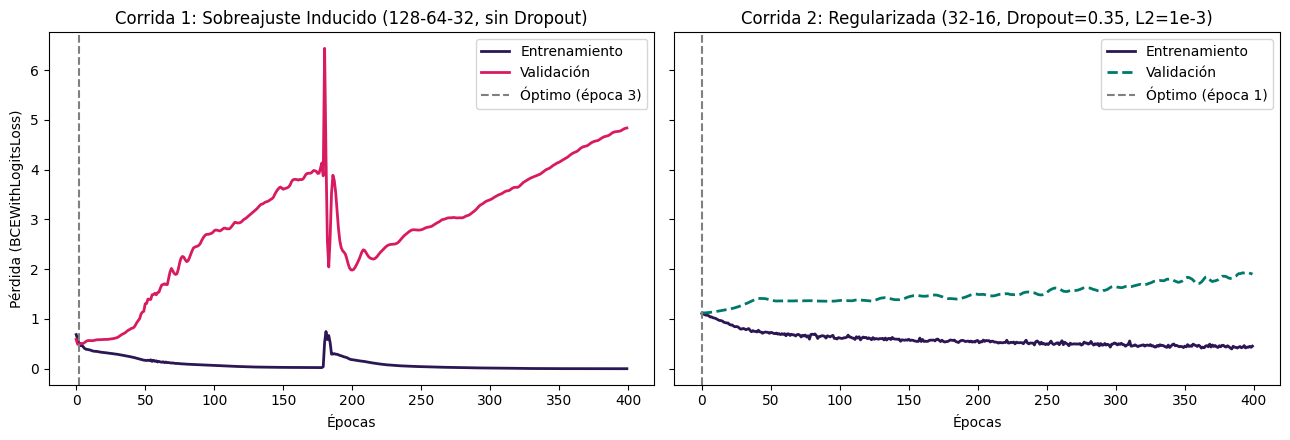

In [14]:
n_features = X_tr_t.shape[1]

# Calcular peso para clase positiva por el desbalance (~29% positivos en el dataset)
n_neg = (y_tr_t == 0).sum().item()
n_pos = (y_tr_t == 1).sum().item()
peso_pos = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32)

# CORRIDA 1: Capacidad alta sin regularización (inducción intencional de sobreajuste)
fijar_semilla(42)
modelo_overfit = CentinelaMLP(n_features, capas_ocultas=(128, 64, 32), p_dropout=0.0)
modelo_overfit, hist_overfit, res_overfit = entrenar_modelo(
    modelo_overfit, X_tr_t, y_tr_t, X_va_t, y_va_t, epocas=400, lr=1e-2, weight_decay=0.0
)

# CORRIDA 2: Arquitectura compacta + Dropout + Regularización L2 (weight_decay)
fijar_semilla(42)
modelo_reg = CentinelaMLP(n_features, capas_ocultas=(32, 16), p_dropout=0.35)
modelo_reg, hist_reg, res_reg = entrenar_modelo(
    modelo_reg, X_tr_t, y_tr_t, X_va_t, y_va_t, epocas=400, lr=5e-3, weight_decay=1e-3, pos_weight=peso_pos
)

# Tabla comparativa cuantitativa (Criterio 3 - Estratégico)
print("=== COMPARATIVA DE EXPERIMENTOS (CRITERIO 3) ===")
print(f"1. Sin Regularizar (128-64-32, p=0.0): Mejor época={res_overfit['mejor_epoca']}, "
      f"Val Loss min={res_overfit['min_val_loss']:.4f}, Brecha={res_overfit['brecha_val_train']:.4f}")
print(f"2. Regularizado    (32-16, p=0.35, L2): Mejor época={res_reg['mejor_epoca']}, "
      f"Val Loss min={res_reg['min_val_loss']:.4f}, Brecha={res_reg['brecha_val_train']:.4f}")

# Gráfica comparativa de curvas de pérdida
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].plot(hist_overfit["train"], label="Entrenamiento", color="#2c1654", lw=2)
axes[0].plot(hist_overfit["val"], label="Validación", color="#d81b60", lw=2)
axes[0].axvline(res_overfit["mejor_epoca"] - 1, color="gray", ls="--", label=f"Óptimo (época {res_overfit['mejor_epoca']})")
axes[0].set_title("Corrida 1: Sobreajuste Inducido (128-64-32, sin Dropout)")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Pérdida (BCEWithLogitsLoss)")
axes[0].legend()

axes[1].plot(hist_reg["train"], label="Entrenamiento", color="#2c1654", lw=2)
axes[1].plot(hist_reg["val"], label="Validación", color="#00796b", ls="--", lw=2)
axes[1].axvline(res_reg["mejor_epoca"] - 1, color="gray", ls="--", label=f"Óptimo (época {res_reg['mejor_epoca']})")
axes[1].set_title("Corrida 2: Regularizada (32-16, Dropout=0.35, L2=1e-3)")
axes[1].set_xlabel("Épocas")
axes[1].legend()

plt.tight_layout()
plt.savefig("curvas_perdida_fase1.png", dpi=300)
plt.show()

Bloque C: Calibración de Umbral en Validación y Evaluación Única en Prueba

In [15]:
# 1. Calibración del umbral EN VALIDACIÓN (nunca en prueba)
modelo_reg.eval()
with torch.no_grad():
    probs_val = torch.sigmoid(modelo_reg(X_va_t)).numpy().ravel()

# Buscamos el umbral que maximice F2-score (da el doble de peso al Recall que a la Precisión,
# porque un Falso Negativo de tizón tardío destruye el cultivo)
umbrales = np.linspace(0.20, 0.70, 51)
mejor_umbral = 0.50
mejor_f2 = -1.0

for u in umbrales:
    preds_u = (probs_val >= u).astype(int)
    p, r, _, _ = precision_recall_fscore_support(y_val, preds_u, pos_label=1, zero_division=0)

    # Extraemos el valor escalar correspondiente a la clase positiva (índice 1 de los arrays o usando average='binary')
    # Al especificar pos_label=1, sklearn devuelve arrays donde el valor de la clase 1 está en la posición de la clase elegida.
    # Para asegurar que sea escalar, podemos calcularlo usando precisión y recall específicos de la clase de interés:
    p_class1 = p[1] if len(p) > 1 else p[0]
    r_class1 = r[1] if len(r) > 1 else r[0]

    f2 = (5 * p_class1 * r_class1) / (4 * p_class1 + r_class1 + 1e-8)
    if f2 > mejor_f2:
        mejor_f2 = f2
        mejor_umbral = u

print(f"Umbral seleccionado en Validación (criterio F2-score): {mejor_umbral:.2f} (F2_val={mejor_f2:.4f})")

Umbral seleccionado en Validación (criterio F2-score): 0.48 (F2_val=0.6079)



=== LÍNEA BASE (CLASE MAYORITARIA EN TEST) ===
Exactitud Baseline: 0.3522
Recall Tizón Tardío Baseline: 0.0000

=== RESULTADOS MLP REGULARIZADO EN TEST (Umbral = 0.48) ===
Exactitud MLP: 0.6640
ROC-AUC MLP:   0.6830

Reporte por clase:
                  precision    recall  f1-score   support

    Negativo (0)     0.5769    0.1724    0.2655        87
Tizón Tardío (1)     0.6742    0.9313    0.7822       160

        accuracy                         0.6640       247
       macro avg     0.6256    0.5518    0.5238       247
    weighted avg     0.6399    0.6640    0.6002       247



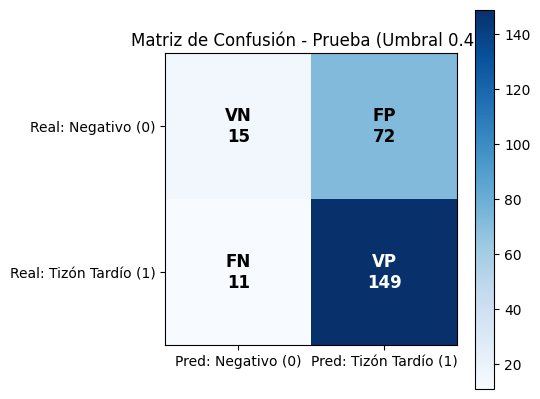

In [16]:
# 2. EVALUACIÓN FINAL (UNA SOLA VEZ EN EL CONJUNTO DE PRUEBA)
with torch.no_grad():
    probs_test = torch.sigmoid(modelo_reg(X_te_t)).numpy().ravel()

preds_test = (probs_test >= mejor_umbral).astype(int)

# Línea base trivial: clase mayoritaria (siempre predice 0 = sin tizón tardío)
clase_mayoritaria = int(np.bincount(y_train.astype(int)).argmax())
preds_baseline = np.full_like(y_test, fill_value=clase_mayoritaria)

print("\n=== LÍNEA BASE (CLASE MAYORITARIA EN TEST) ===")
print(f"Exactitud Baseline: {accuracy_score(y_test, preds_baseline):.4f}")
print(f"Recall Tizón Tardío Baseline: {recall_score(y_test, preds_baseline, pos_label=1):.4f}")

print(f"\n=== RESULTADOS MLP REGULARIZADO EN TEST (Umbral = {mejor_umbral:.2f}) ===")
print(f"Exactitud MLP: {accuracy_score(y_test, preds_test):.4f}")
print(f"ROC-AUC MLP:   {roc_auc_score(y_test, probs_test):.4f}")
print("\nReporte por clase:")
print(classification_report(y_test, preds_test, target_names=["Negativo (0)", "Tizón Tardío (1)"], digits=4))

# 3. Matriz de confusión visual para el informe
cm = confusion_matrix(y_test, preds_test)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred: Negativo (0)", "Pred: Tizón Tardío (1)"])
ax.set_yticklabels(["Real: Negativo (0)", "Real: Tizón Tardío (1)"])
ax.set_title(f"Matriz de Confusión - Prueba (Umbral {mejor_umbral:.2f})")

etiquetas_celda = [["VN", "FP"], ["FN", "VP"]]
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, f"{etiquetas_celda[i][j]}\n{cm[i, j]}", ha="center", va="center", color=color, fontsize=12, fontweight="bold")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("matriz_confusion_fase1.png", dpi=300)
plt.show()

# Guardar checkpoint final de la Fase 1
torch.save(modelo_reg.state_dict(), "centinela_fase1_mlp.pt")